Total valid samples ready for modeling: 18201

=== RANDOM FOREST FUTURE DECAY PREDICTION PERFORMANCE ===
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3379
           1       0.75      0.84      0.79       262

    accuracy                           0.97      3641
   macro avg       0.87      0.91      0.89      3641
weighted avg       0.97      0.97      0.97      3641



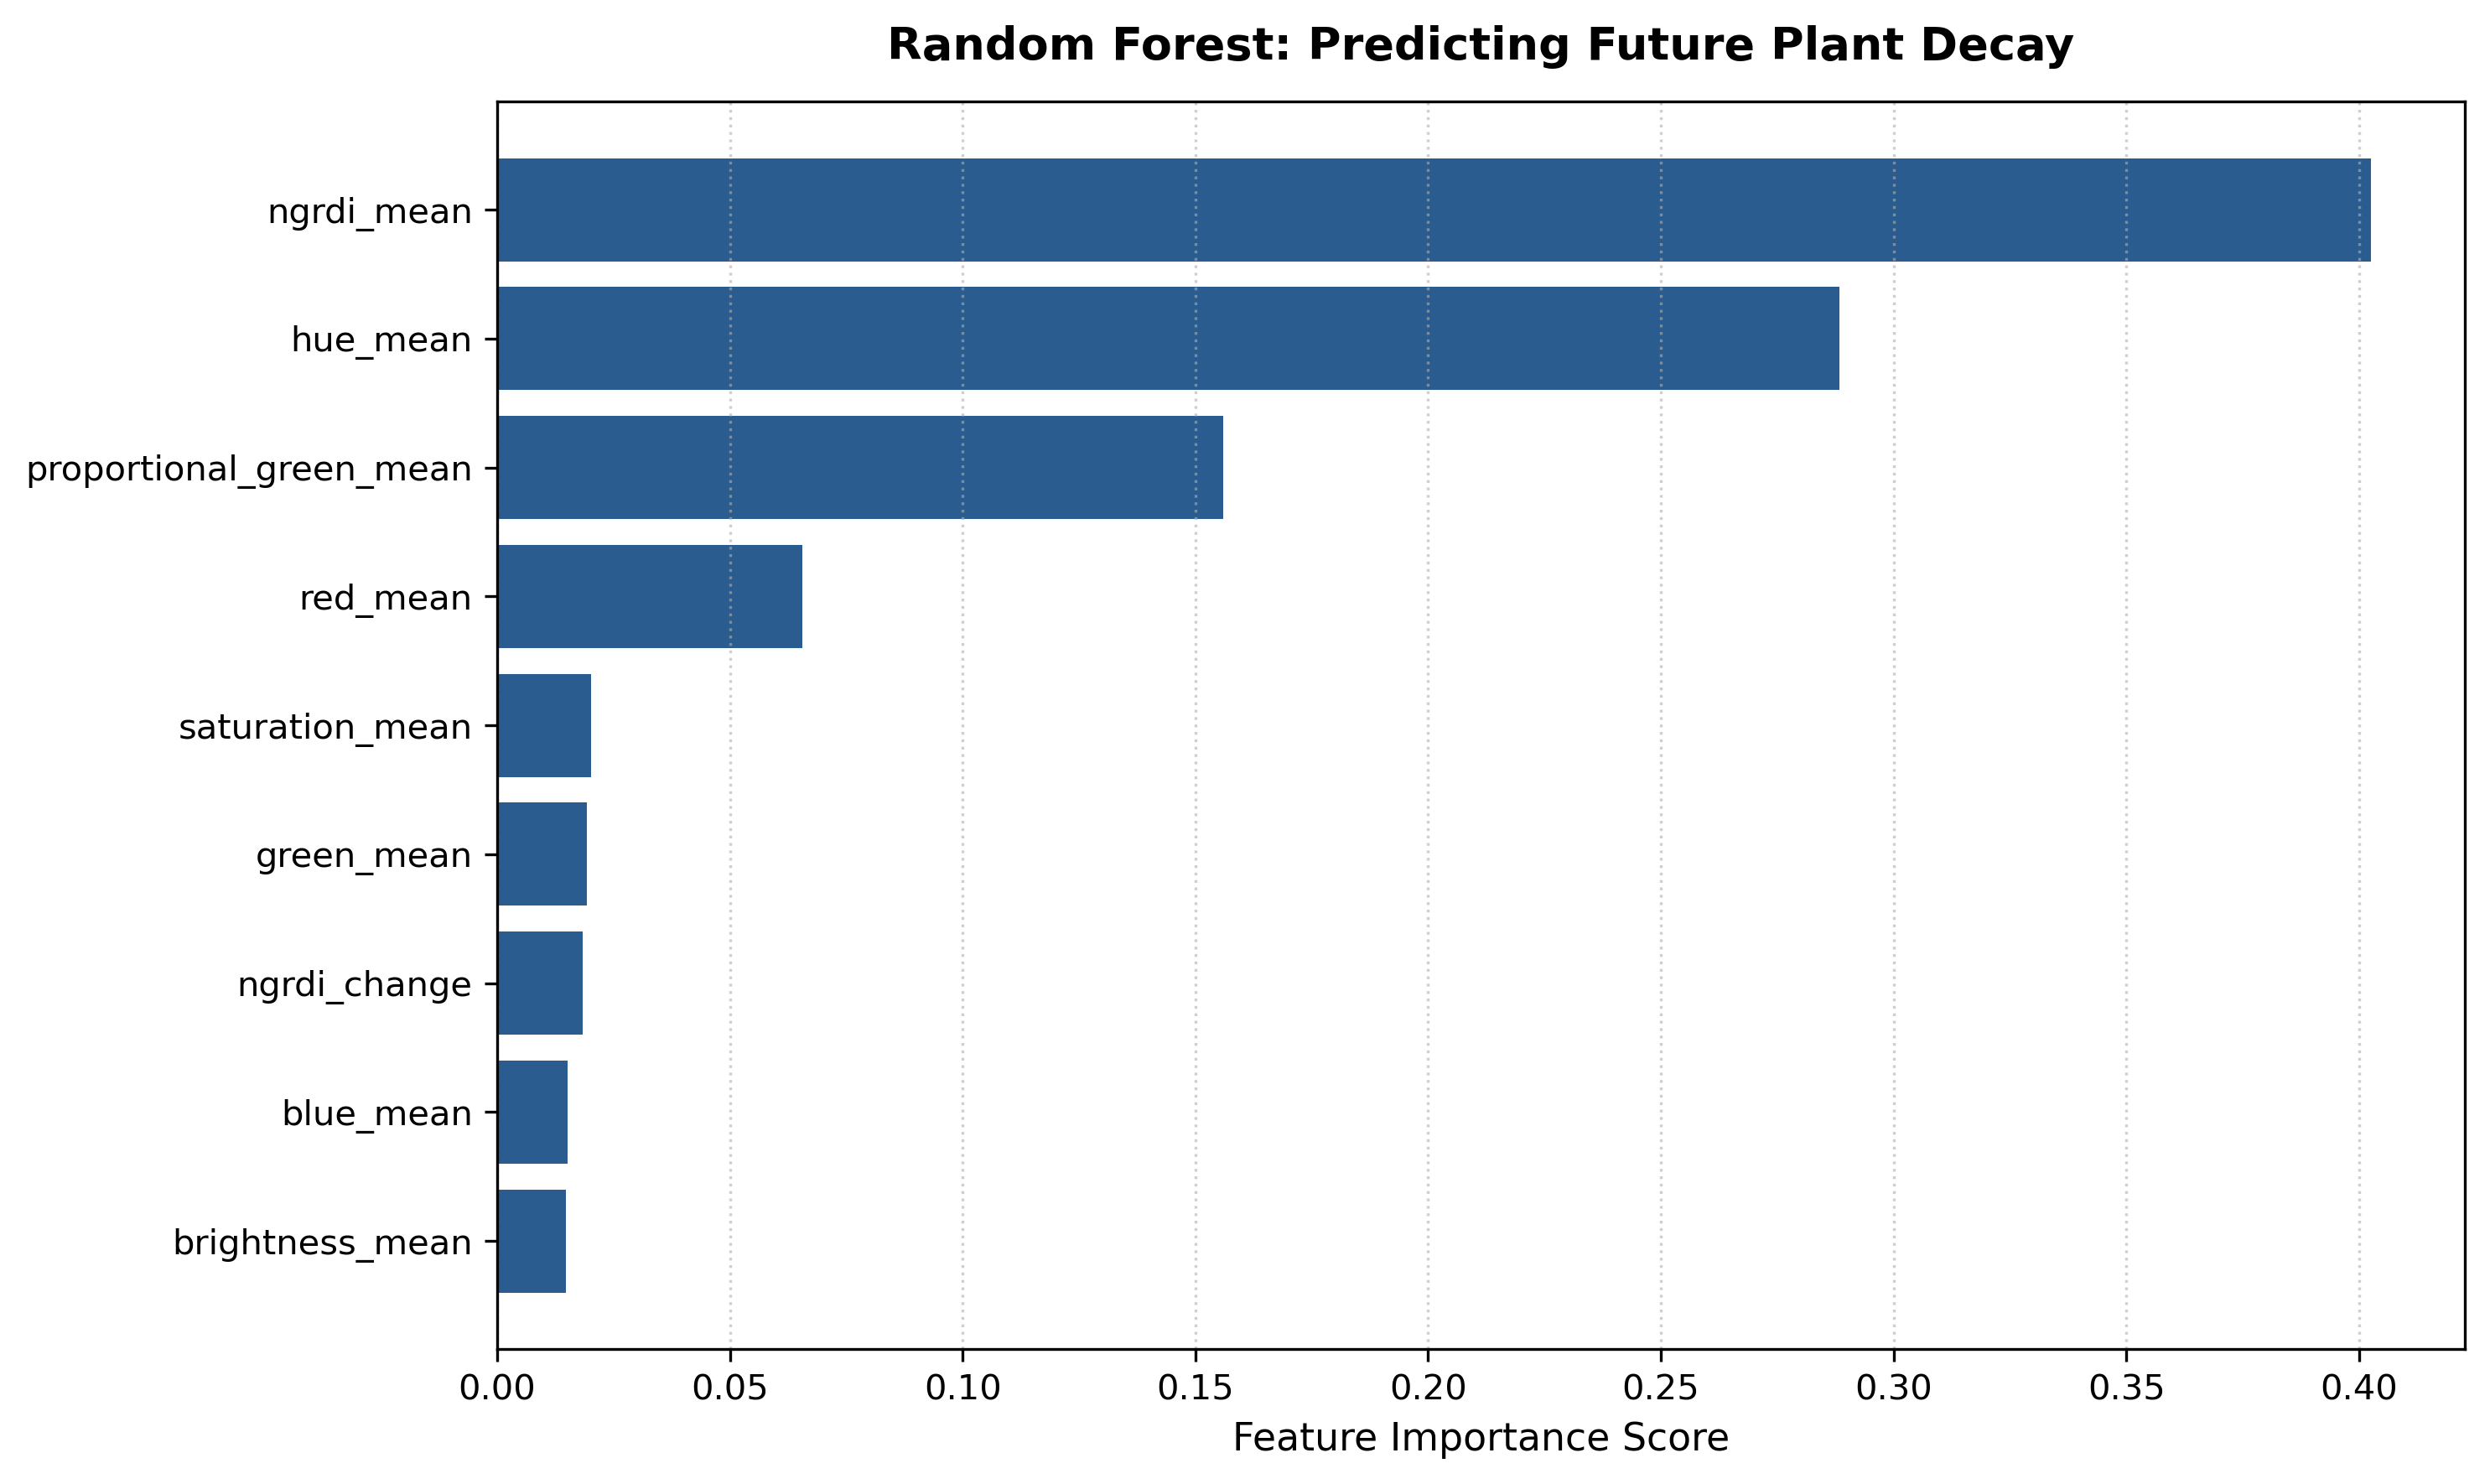

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

#Load datasets
design_df = pd.read_csv("design.csv")
features_df = pd.read_csv("features.csv")

# Merge using 'sample_key' using explicit suffixes to prevent naming collisions
df = pd.merge(features_df, design_df, on='sample_key', how='inner', suffixes=('', '_des'))

# Identify plant_id and date columns
plant_col = 'plant_id' if 'plant_id' in df.columns else [c for c in df.columns if 'plant_id' in c.lower()][0]
date_candidates = [c for c in df.columns if 'date' in c.lower()]
date_col = date_candidates[0] if date_candidates else 'date'

# Convert date and sort chronologically per plant
df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
df = df.sort_values(by=[plant_col, date_col])

#Engineer Longitudinal Features (Rate of Change / Velocity)
df['ngrdi_lag'] = df.groupby(plant_col)['ngrdi_mean'].shift(1)
df['ngrdi_change'] = df['ngrdi_mean'] - df['ngrdi_lag'] 

#Define FUTURE Decay Target (Predicting if the plant WILL decay in the next time step)
DECAY_THRESHOLD = 0.02
df['future_ngrdi'] = df.groupby(plant_col)['ngrdi_mean'].shift(-1)
df['will_decay_soon'] = (df['future_ngrdi'] < DECAY_THRESHOLD).astype(int)

# 5. Select Predictive Features
feature_cols = [
    'red_mean', 'green_mean', 'blue_mean', 
    'hue_mean', 'saturation_mean', 'brightness_mean', 
    'ngrdi_mean', 'proportional_green_mean', 'ngrdi_change'
]
target_col = 'will_decay_soon'

# Clean missing values resulting from shifts/lags without wiping out the dataset
model_df = df[feature_cols + [target_col]].dropna()
X = model_df[feature_cols]
y = model_df[target_col]

print(f"Total valid samples ready for modeling: {len(X)}")

#Stratified Train/Test Split
has_both_classes = y.nunique() > 1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, 
    stratify=y if has_both_classes else None
)

#Train Random Forest Classifier
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
rf_classifier.fit(X_train, y_train)

#Evaluate Performance
y_pred = rf_classifier.predict(X_test)
print("\n=== RANDOM FOREST FUTURE DECAY PREDICTION PERFORMANCE ===")
print(classification_report(y_test, y_pred, zero_division=0))

#Plot Feature Importance Chart
importances = rf_classifier.feature_importances_
sorted_idx = np.argsort(importances)

plt.figure(figsize=(10, 6), dpi=300)
plt.barh(range(len(feature_cols)), importances[sorted_idx], color='#2b5c8f')
plt.yticks(range(len(feature_cols)), np.array(feature_cols)[sorted_idx])
plt.xlabel("Feature Importance Score", fontsize=11)
plt.title("Random Forest: Predicting Future Plant Decay", fontsize=13, fontweight='bold', pad=12)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


Total valid samples ready for modeling: 18201

=== RANDOM FOREST FUTURE DECAY PREDICTION PERFORMANCE ===
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3379
           1       0.76      0.85      0.80       262

    accuracy                           0.97      3641
   macro avg       0.87      0.91      0.89      3641
weighted avg       0.97      0.97      0.97      3641



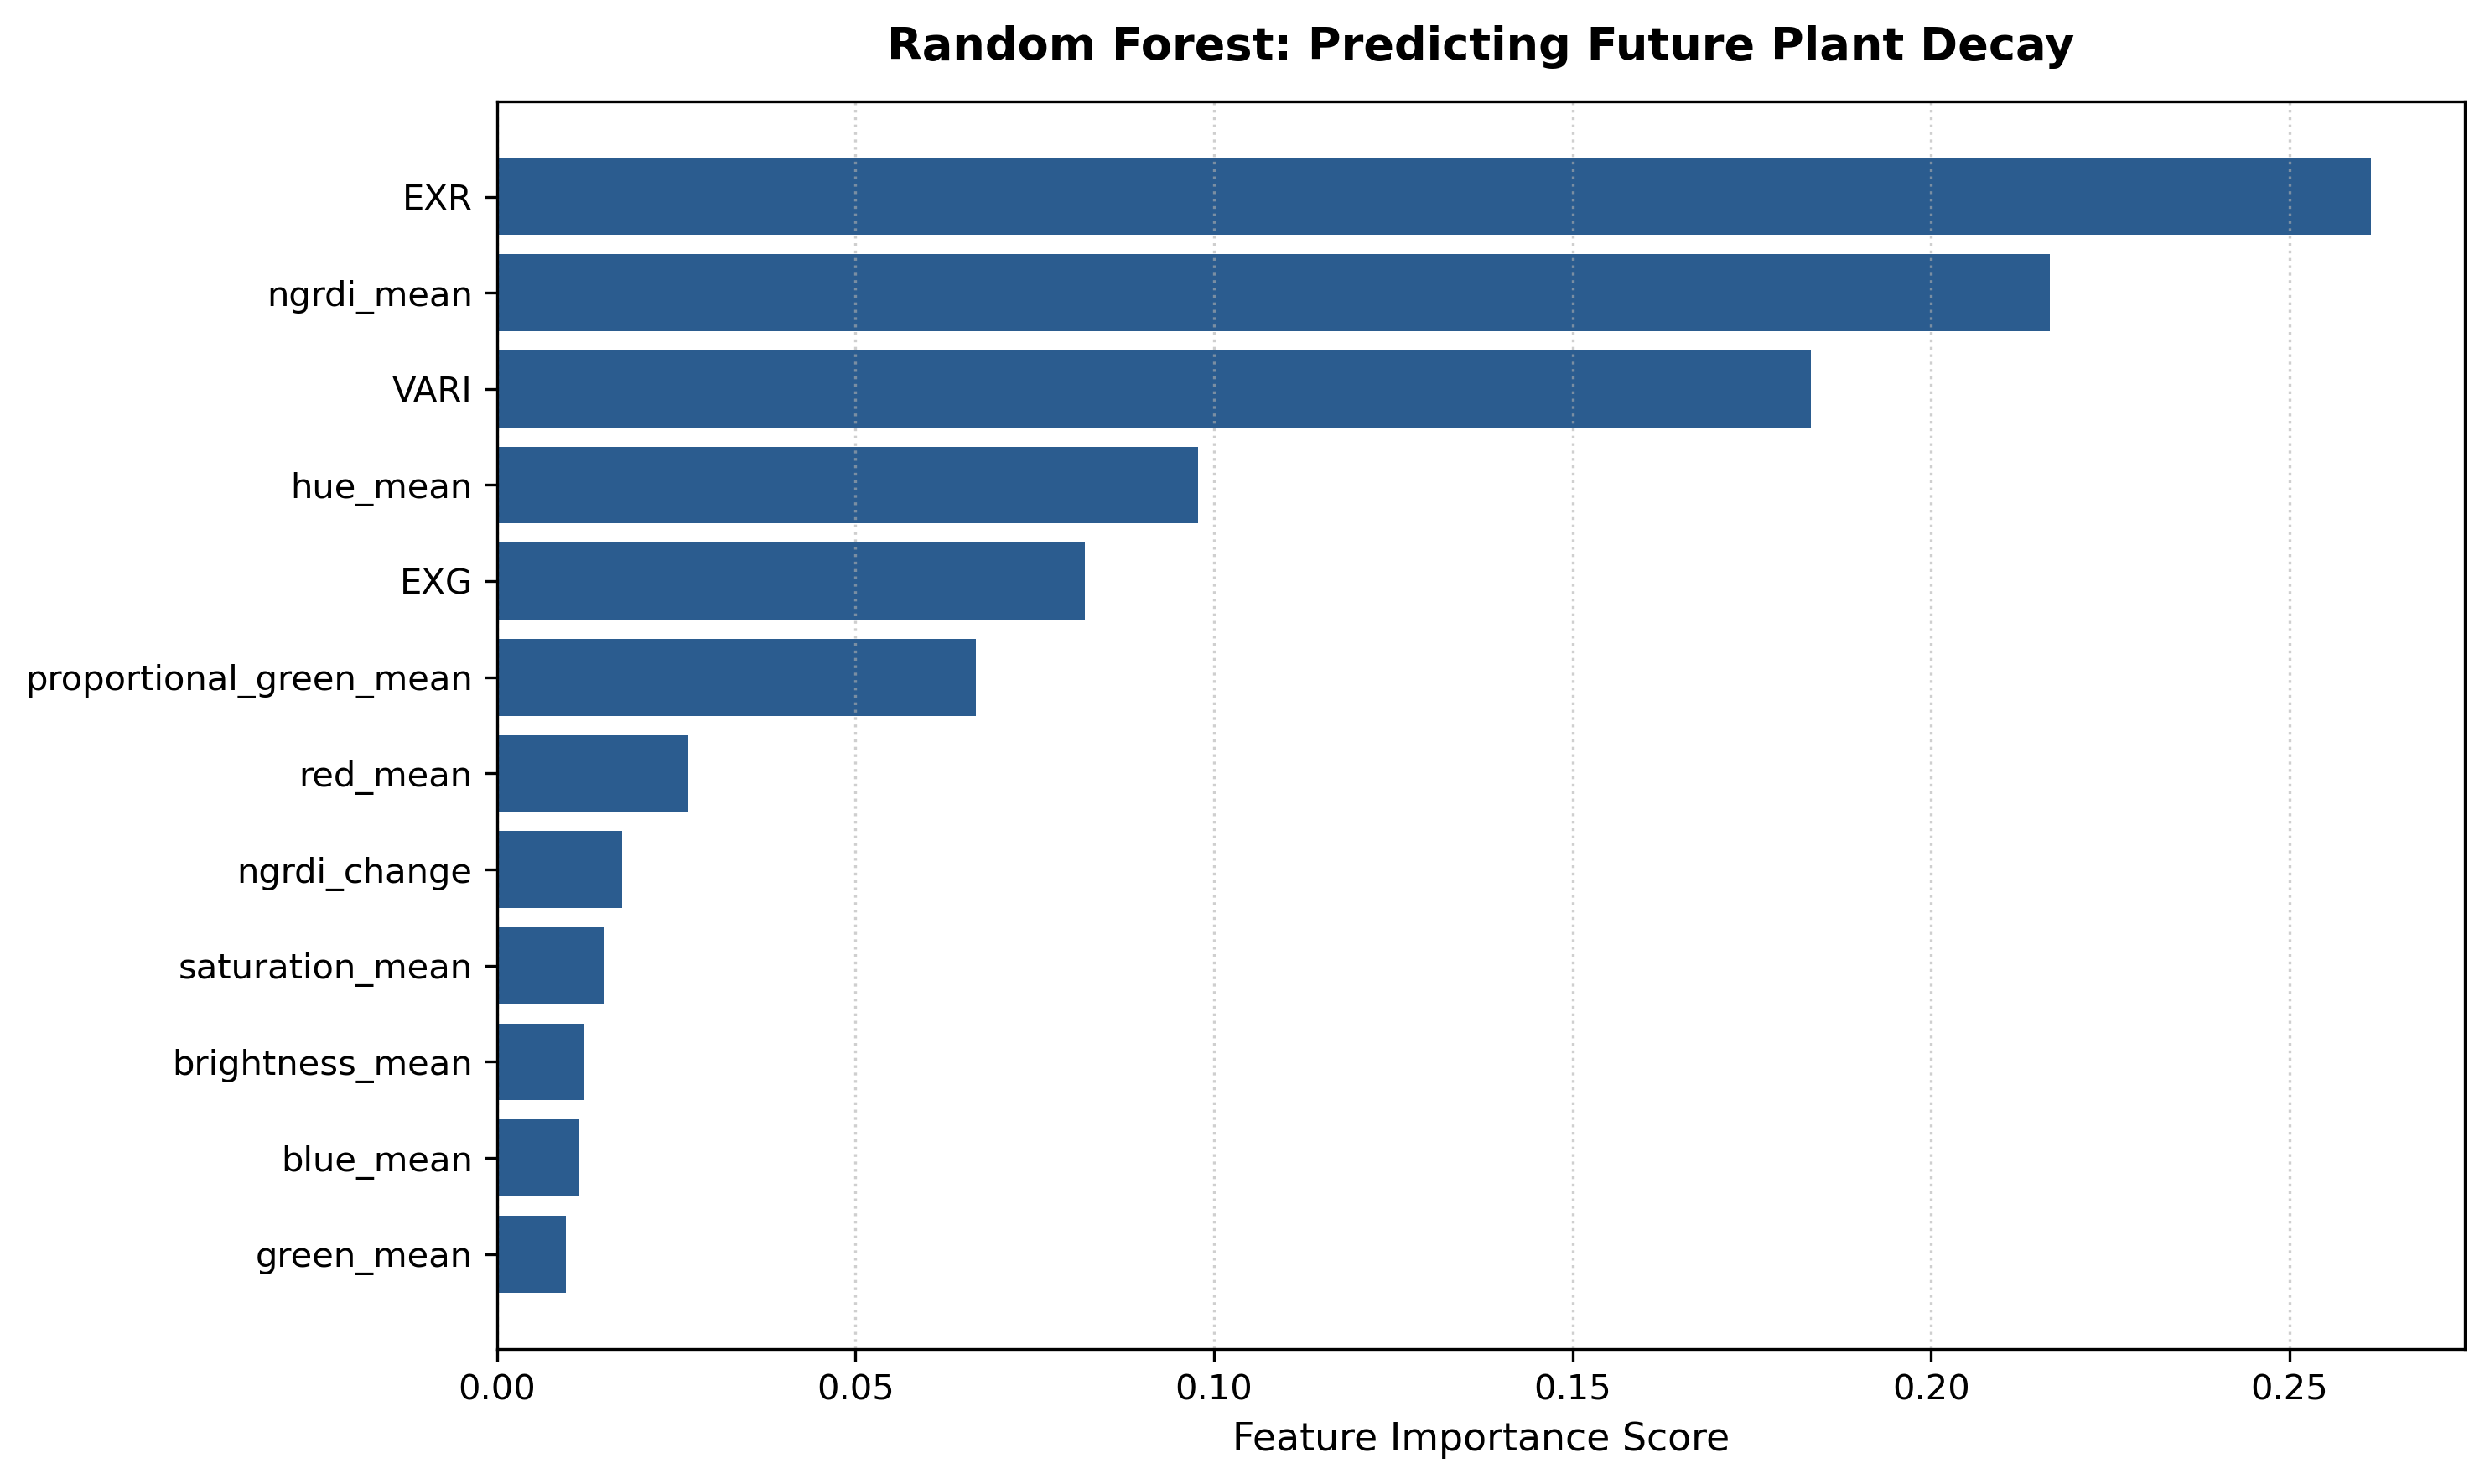

In [11]:
#Calculate Vegetation Indices
R = df['proportional_red_mean']
G = df['proportional_green_mean']
B = df['proportional_blue_mean']

df['EXG'] = 2 * G - R - B
df['EXR'] = 1.4 * R - G

# Add a small epsilon (1e-6) to VARI denominator to prevent division by zero errors
df['VARI'] = (G - R) / (G + R - B + 1e-6) 

#Define FUTURE Decay Target (Predicting if the plant WILL decay in the next time step)
DECAY_THRESHOLD = 0.02
df['future_ngrdi'] = df.groupby(plant_col)['ngrdi_mean'].shift(-1)
df['will_decay_soon'] = (df['future_ngrdi'] < DECAY_THRESHOLD).astype(int)

#Select Predictive Features
feature_cols = [
    'red_mean', 'green_mean', 'blue_mean', 
    'hue_mean', 'saturation_mean', 'brightness_mean', 
    'ngrdi_mean', 'proportional_green_mean', 'ngrdi_change',
    'EXG', 'EXR', 'VARI'
]
target_col = 'will_decay_soon'

#Clean missing values resulting from shifts/lags without wiping out the dataset
model_df = df[feature_cols + [target_col]].dropna()
X = model_df[feature_cols]
y = model_df[target_col]

print(f"Total valid samples ready for modeling: {len(X)}")

#Stratified Train/Test Split
has_both_classes = y.nunique() > 1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, 
    stratify=y if has_both_classes else None
)

#Train Random Forest Classifier
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
rf_classifier.fit(X_train, y_train)

#Evaluate Performance
y_pred = rf_classifier.predict(X_test)
print("\n=== RANDOM FOREST FUTURE DECAY PREDICTION PERFORMANCE ===")
print(classification_report(y_test, y_pred, zero_division=0))

#Plot Feature Importance Chart
importances = rf_classifier.feature_importances_
sorted_idx = np.argsort(importances)

plt.figure(figsize=(10, 6), dpi=300)
plt.barh(range(len(feature_cols)), importances[sorted_idx], color='#2b5c8f')
plt.yticks(range(len(feature_cols)), np.array(feature_cols)[sorted_idx])
plt.xlabel("Feature Importance Score", fontsize=11)
plt.title("Random Forest: Predicting Future Plant Decay", fontsize=13, fontweight='bold', pad=12)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

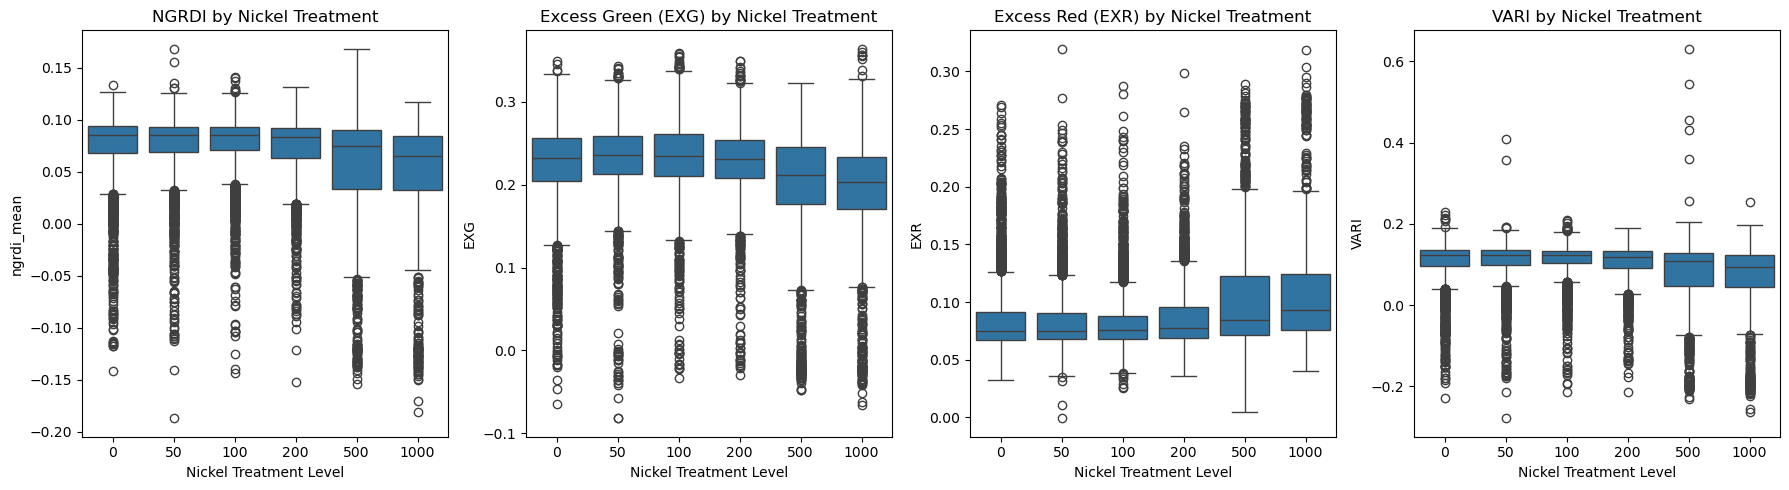

In [13]:
import seaborn as sns

#Calculate Survival (20,000 pixel max area threshold)
# Group by plant_id to find the maximum area reached across all imaging rounds
max_area_per_plant = df.groupby('plant_id')['area_px'].max().reset_index()
max_area_per_plant['survived'] = (max_area_per_plant['area_px'] > 20000).astype(int)
max_area_per_plant = max_area_per_plant.rename(columns={'area_px': 'max_area_px'})

# Merge the binary survival outcome back into the main dataset
df = pd.merge(df, max_area_per_plant[['plant_id', 'survived', 'max_area_px']], on='plant_id', how='left')

# 5. Visualize NGRDI, EXG, and EXR across Nickel Treatments
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

sns.boxplot(data=df, x='treatment', y='ngrdi_mean', ax=axes[0])
axes[0].set_title('NGRDI by Nickel Treatment')
axes[0].set_xlabel('Nickel Treatment Level')

sns.boxplot(data=df, x='treatment', y='EXG', ax=axes[1])
axes[1].set_title('Excess Green (EXG) by Nickel Treatment')
axes[1].set_xlabel('Nickel Treatment Level')

sns.boxplot(data=df, x='treatment', y='EXR', ax=axes[2])
axes[2].set_title('Excess Red (EXR) by Nickel Treatment')
axes[2].set_xlabel('Nickel Treatment Level')

sns.boxplot(data=df, x='treatment', y='VARI', ax=axes[3])
axes[3].set_title('VARI by Nickel Treatment')
axes[3].set_xlabel('Nickel Treatment Level')

plt.tight_layout()
plt.show()

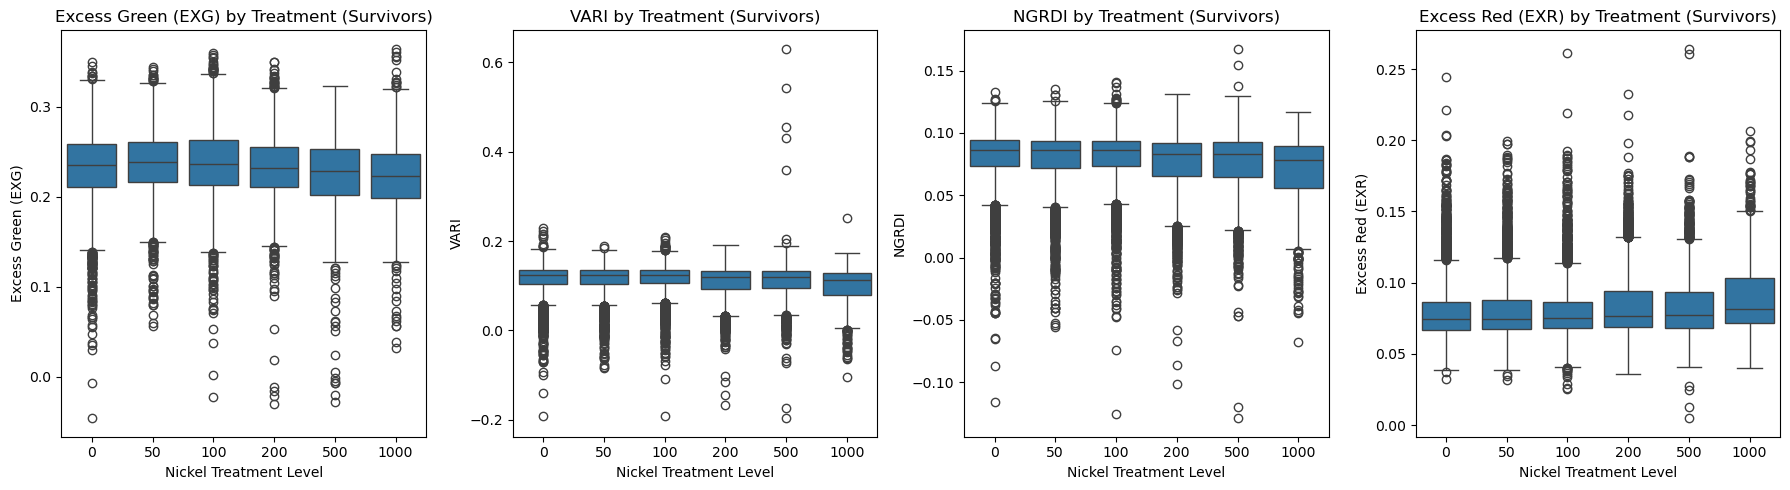

In [15]:
#Isolate Survivors Only
survivors_df = df[df['survived'] == 1].copy()

#Generate the Visualizations
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

#Plot Excess Green (EXG)
sns.boxplot(data=survivors_df, x='treatment', y='EXG', ax=axes[0])
axes[0].set_title('Excess Green (EXG) by Treatment (Survivors)')
axes[0].set_xlabel('Nickel Treatment Level')
axes[0].set_ylabel('Excess Green (EXG)')

#Plot VARI
sns.boxplot(data=survivors_df, x='treatment', y='VARI', ax=axes[1])
axes[1].set_title('VARI by Treatment (Survivors)')
axes[1].set_xlabel('Nickel Treatment Level')
axes[1].set_ylabel('VARI')

#Plot NGRDI
sns.boxplot(data=survivors_df, x='treatment', y='ngrdi_mean', ax=axes[2])
axes[2].set_title('NGRDI by Treatment (Survivors)')
axes[2].set_xlabel('Nickel Treatment Level')
axes[2].set_ylabel('NGRDI')

sns.boxplot(data=survivors_df, x='treatment', y='EXR', ax=axes[3])
axes[3].set_title('Excess Red (EXR) by Treatment (Survivors)')
axes[3].set_xlabel('Nickel Treatment Level')
axes[3].set_ylabel('Excess Red (EXR)')

plt.tight_layout()
plt.show()

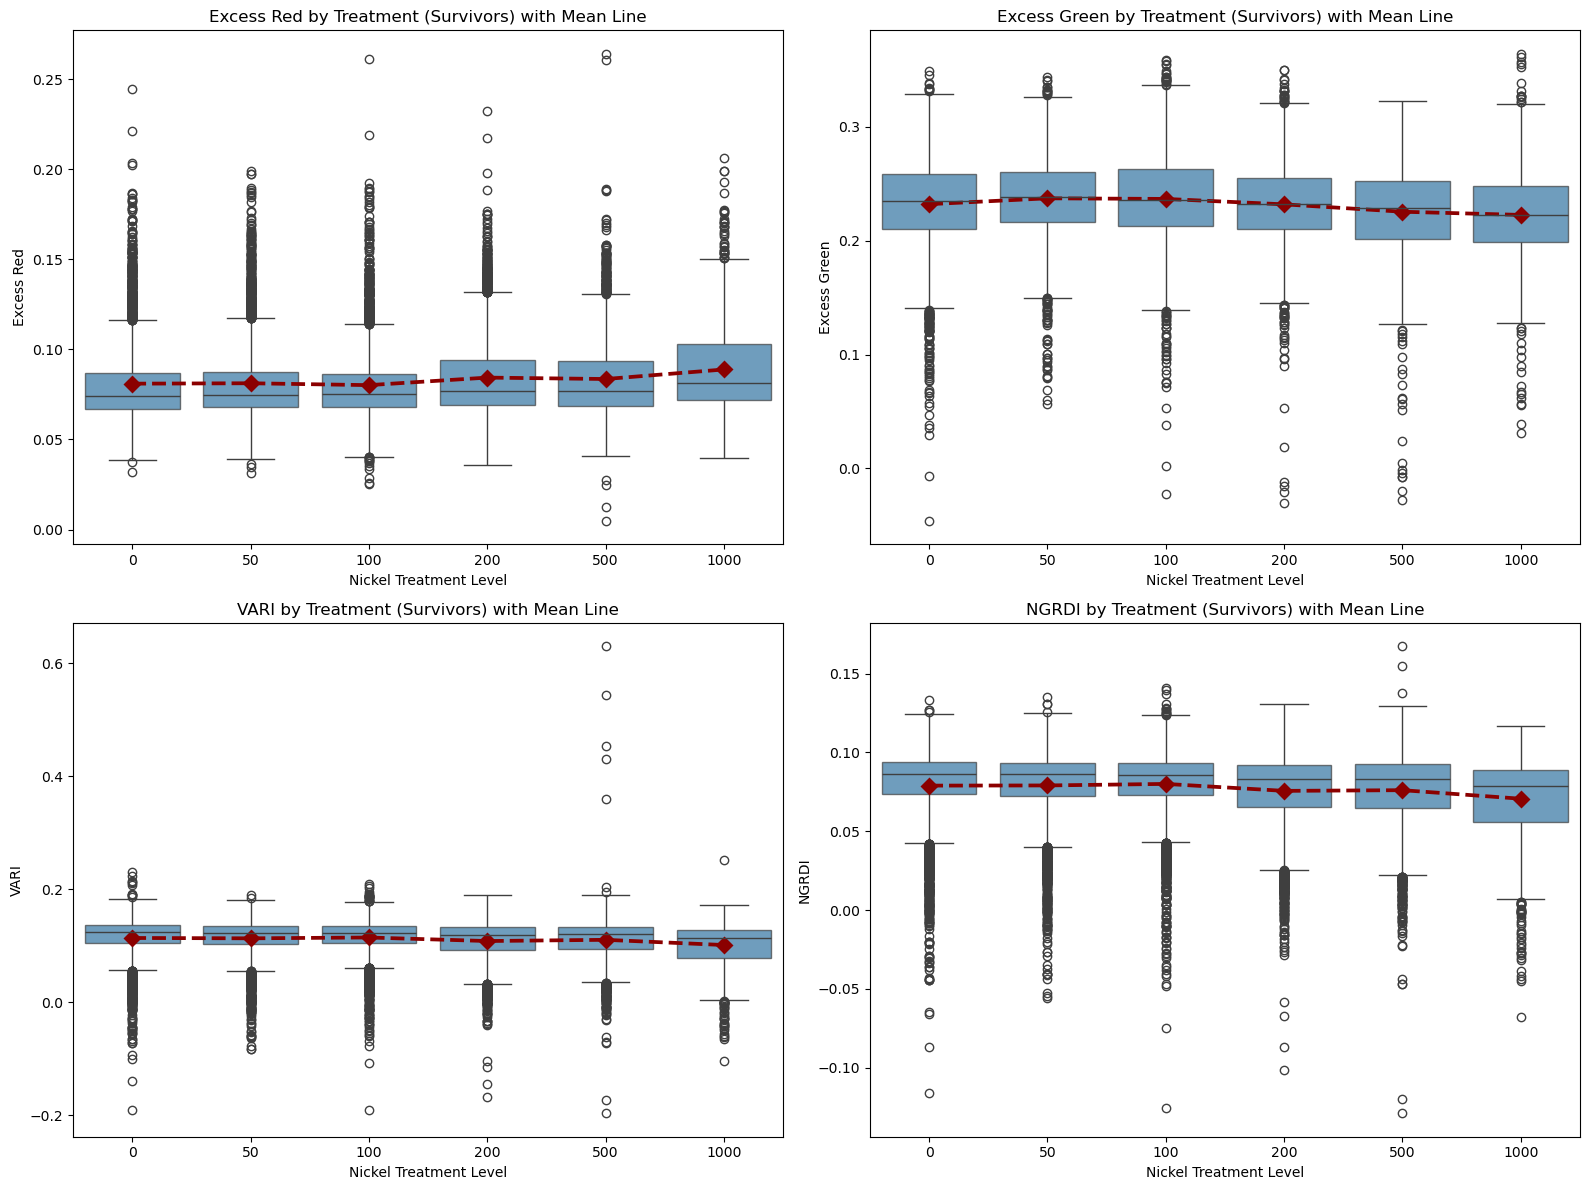

In [17]:
#Generate the Visualizations with Mean Lines Overlay
metrics = {'EXR': 'Excess Red', 'EXG': 'Excess Green', 'VARI': 'VARI', 'ngrdi_mean': 'NGRDI'}
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (metric, title) in enumerate(metrics.items()):
    # Create the standard boxplot, adding transparency (alpha) to make the line pop
    sns.boxplot(data=survivors_df, x='treatment', y=metric, ax=axes[i], boxprops={'alpha': 0.7})
    
    # Overlay the mean line connecting the treatments
    sns.pointplot(data=survivors_df, x='treatment', y=metric, ax=axes[i], 
                  color='darkred', linestyles='--', markers='D', errorbar=None)
    
    axes[i].set_title(f'{title} by Treatment (Survivors) with Mean Line')
    axes[i].set_xlabel('Nickel Treatment Level')
    axes[i].set_ylabel(title)

plt.tight_layout()
plt.show()

Linear Mixed Effects Model

The model was created in R, based on interaction terms (treatment level, time and status {Dead vs Alive}) there was a significant relationship between EXR or EXG and the concentration of nickel in the soil. However, a Q-Q plot created from the residuals showed heavy skewing on the tails. This indicates that the outliers are skewing the results from the LMM. Therefore, until further tweaking is done, the model results are unreliable. 